In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/Churn_Modelling.csv')

display(df.head())

display(df.describe())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


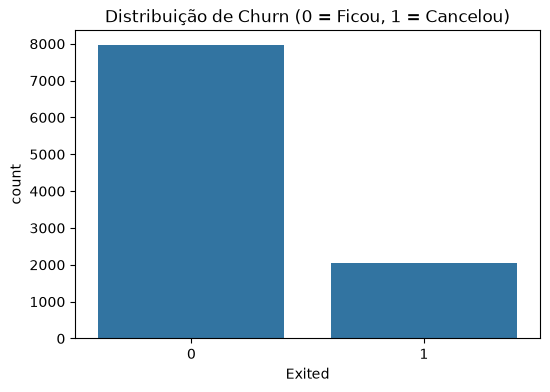

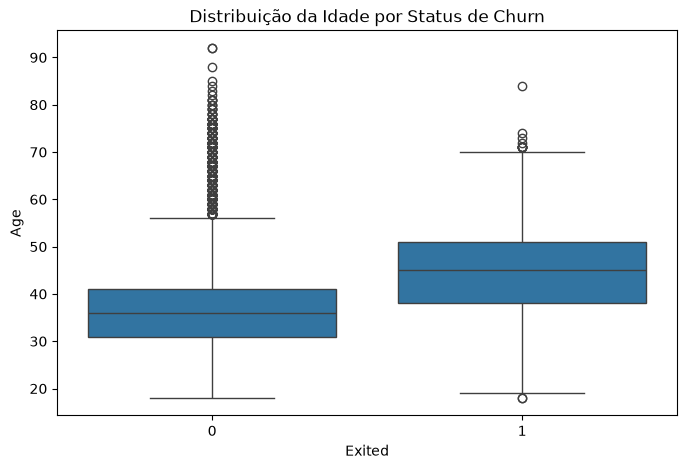

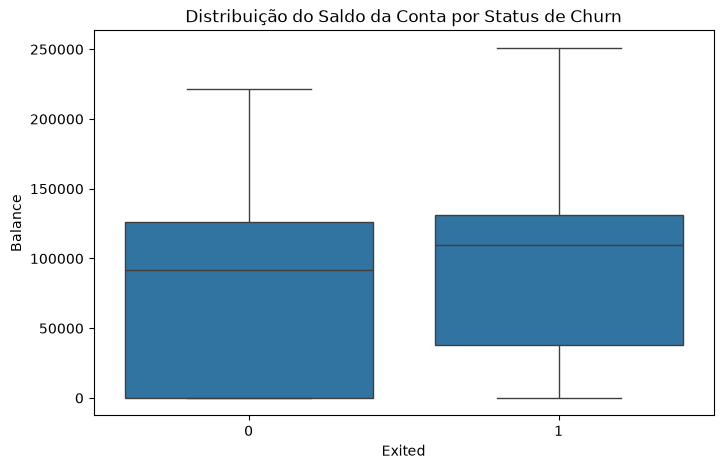

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Exited')
plt.title('Distribuição de Churn (0 = Ficou, 1 = Cancelou)')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Exited', y='Age')
plt.title('Distribuição da Idade por Status de Churn')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Exited', y='Balance')
plt.title('Distribuição do Saldo da Conta por Status de Churn')
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pickle

df_preparado = pd.get_dummies(df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1), drop_first=True)

X = df_preparado.drop('Exited', axis=1)
y = df_preparado['Exited']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo_real = RandomForestClassifier(n_estimators=100, random_state=42)
print("A treinar o modelo com milhares de dados...")
modelo_real.fit(X_train, y_train)

previsoes = modelo_real.predict(X_test)
print("\nRelatório de Classificação:\n")
print(classification_report(y_test, previsoes))

with open('../modelos/modelo.pkl', 'wb') as arquivo:
    pickle.dump(modelo_real, arquivo)
print("\nModelo real guardado com sucesso em 'modelos/modelo.pkl'!")

A treinar o modelo com milhares de dados...

Relatório de Classificação:

              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.76      0.47      0.58       393

    accuracy                           0.87      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.86      0.87      0.85      2000


Modelo real guardado com sucesso em 'modelos/modelo.pkl'!
